In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import pandas as pd
import numpy as np
from PIL import Image
import os
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score



In [24]:
class ChestXrayDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        self.labels = self.data['Finding Labels'].str.get_dummies(sep='|')
        
        # Pre-build image path mapping for faster loading
        self.img_paths = {}
        print("Building image path index...")
        for root, _, files in os.walk(self.img_dir):
            for file in files:
                if file.endswith('.png'):
                    self.img_paths[file] = os.path.join(root, file)
        print(f"Indexed {len(self.img_paths)} images")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_name = self.data.iloc[idx]['Image Index']
        img_path = self.img_paths.get(img_name)
        
        if img_path is None:
            raise FileNotFoundError(f"Image {img_name} not found in {self.img_dir}")
        
        image = Image.open(img_path).convert('RGB')
        
        label = torch.tensor(
            self.labels.iloc[idx].values,
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, label, idx

In [25]:
# Data augmentation and normalization for training
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

# Simpler transform for validation/test
transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

# Create full dataset (without transforms initially)
dataset = ChestXrayDataset(
    csv_file='Data_Entry_2017.csv',
    img_dir='images-224/images-224',
    transform=None
)

# Split indices for train and validation
indices = list(range(len(dataset)))
train_indices, val_indices = train_test_split(
    indices, 
    test_size=0.2, 
    random_state=42,
    shuffle=True
)

print(f"Total samples: {len(dataset)}")
print(f"Training samples: {len(train_indices)}")
print(f"Validation samples: {len(val_indices)}")

# Custom Subset class that applies transforms
class TransformedSubset(torch.utils.data.Subset):
    def __init__(self, dataset, indices, transform=None):
        super().__init__(dataset, indices)
        self.transform = transform
        
    def __getitem__(self, idx):
        image, label, original_idx = self.dataset[self.indices[idx]]
        if self.transform:
            image = self.transform(image)
        return image, label, original_idx
    
    def __getitems__(self, indices):
        # Required for newer PyTorch versions
        return [self.__getitem__(idx) for idx in indices]

# Create datasets with appropriate transforms
train_dataset = TransformedSubset(dataset, train_indices, transform_train)
val_dataset = TransformedSubset(dataset, val_indices, transform_val)

# Create data loaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=0,  # Set to 0 to avoid multiprocessing issues
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0,  # Set to 0 to avoid multiprocessing issues
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# Test a batch to ensure everything works
test_images, test_labels, test_indices = next(iter(train_loader))
print(f"\nBatch test successful!")
print(f"Image shape: {test_images.shape}")
print(f"Labels shape: {test_labels.shape}")
print(f"Indices shape: {test_indices.shape}")

Building image path index...
Indexed 112120 images
Total samples: 112120
Training samples: 89696
Validation samples: 22424
Training batches: 2803
Validation batches: 701

Batch test successful!
Image shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32, 15])
Indices shape: torch.Size([32])


In [26]:
class ChestXrayResNet(nn.Module):
    def __init__(self, num_classes=15, pretrained=True, dropout_rate=0.3):
        super(ChestXrayResNet, self).__init__()
        
        # Load pretrained ResNet18
        if pretrained:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            self.backbone = models.resnet18(weights=weights)
        else:
            self.backbone = models.resnet18(weights=None)
        
        # Extract feature layers (everything except the final FC and pooling)
        self.features = nn.Sequential(
            self.backbone.conv1,
            self.backbone.bn1,
            self.backbone.relu,
            self.backbone.maxpool,
            self.backbone.layer1,
            self.backbone.layer2,
            self.backbone.layer3,
            self.backbone.layer4
        )
        
        # Global Average Pooling
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        
        # Custom classifier head
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(128, num_classes)
        )
        
        # Initialize weights for new layers
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def forward(self, x):
        # Extract features
        x = self.features(x)
        
        # Global pooling
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        
        # Classification
        x = self.classifier(x)
        return x
    
    def get_features(self, x):
        """Extract features before final classification layer"""
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        
        # Get features up to the last layer
        for layer in list(self.classifier.children())[:-1]:
            x = layer(x)
        return x
    
    def freeze_backbone(self):
        """Freeze backbone layers for transfer learning"""
        for param in self.features.parameters():
            param.requires_grad = False
            
    def unfreeze_backbone(self):
        """Unfreeze backbone layers"""
        for param in self.features.parameters():
            param.requires_grad = True
            
    def unfreeze_layer(self, layer_num):
        """Unfreeze specific layer (3 or 4)"""
        if layer_num == 4:
            for param in self.backbone.layer4.parameters():
                param.requires_grad = True
        elif layer_num == 3:
            for param in self.backbone.layer3.parameters():
                param.requires_grad = True
            for param in self.backbone.layer4.parameters():
                param.requires_grad = True

# Initialize model and move to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ChestXrayResNet(num_classes=15, pretrained=True).to(device)

print(f"Model created successfully on {device}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Model created successfully on cuda
Total parameters: 11,856,439
Trainable parameters: 11,856,439


In [27]:
# Calculate class weights for handling imbalanced dataset
print("Calculating class weights...")
temp_dataset = ChestXrayDataset(
    csv_file='Data_Entry_2017.csv',
    img_dir='images-224/images-224',
    transform=None
)

# Get label distribution
label_counts = temp_dataset.labels.sum(axis=0).values
total_samples = len(temp_dataset)

# Calculate positive weights (inverse frequency)
pos_weights = total_samples / (label_counts + 1e-6)
pos_weights_tensor = torch.tensor(pos_weights, dtype=torch.float32).to(device)

print("\nClass distribution (samples per disease):")
for i, (disease, count) in enumerate(zip(temp_dataset.labels.columns, label_counts)):
    print(f"  {disease}: {int(count)} ({count/total_samples*100:.1f}%)")

# Loss function with class balancing
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights_tensor)

# Use SGD optimizer instead of Adam to avoid optree issues
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)

# Learning rate scheduler (removed 'verbose' parameter)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.5, 
    patience=3,
    min_lr=1e-7
)

print("\n" + "="*60)
print("Training Configuration:")
print("="*60)
print(f"  Device: {device}")
print(f"  Optimizer: SGD (lr=0.01, momentum=0.9, weight_decay=1e-4)")
print(f"  Loss: BCEWithLogitsLoss with class weights")
print(f"  Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)")
print("="*60)

Calculating class weights...
Building image path index...
Indexed 112120 images

Class distribution (samples per disease):
  Atelectasis: 11535 (10.3%)
  Cardiomegaly: 2772 (2.5%)
  Consolidation: 4667 (4.2%)
  Edema: 2303 (2.1%)
  Effusion: 13307 (11.9%)
  Emphysema: 2516 (2.2%)
  Fibrosis: 1686 (1.5%)
  Hernia: 227 (0.2%)
  Infiltration: 19870 (17.7%)
  Mass: 5746 (5.1%)
  No Finding: 60412 (53.9%)
  Nodule: 6323 (5.6%)
  Pleural_Thickening: 3385 (3.0%)
  Pneumonia: 1353 (1.2%)
  Pneumothorax: 5298 (4.7%)

Training Configuration:
  Device: cuda
  Optimizer: SGD (lr=0.01, momentum=0.9, weight_decay=1e-4)
  Loss: BCEWithLogitsLoss with class weights
  Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)


In [28]:
def train_epoch(model, loader, optimizer, criterion, epoch):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    pbar = tqdm(loader, desc=f'Training Epoch {epoch}')
    for batch_idx, (images, labels, _) in enumerate(pbar):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()

        total_loss += loss.item()
        
        # Collect predictions for metrics
        with torch.no_grad():
            preds = torch.sigmoid(outputs.detach())
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
        
        # Update progress bar
        if batch_idx % 10 == 0:
            pbar.set_postfix({
                'loss': f'{loss.item():.4f}',
                'avg': f'{total_loss/(batch_idx+1):.4f}'
            })
    
    # Calculate epoch metrics
    avg_loss = total_loss / len(loader)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    
    # Calculate AUC per class
    auc_scores = []
    for i in range(all_labels.shape[1]):
        if len(np.unique(all_labels[:, i])) > 1:
            try:
                auc = roc_auc_score(all_labels[:, i], all_preds[:, i])
                auc_scores.append(auc)
            except:
                pass
    
    avg_auc = np.mean(auc_scores) if auc_scores else 0.0
    
    return avg_loss, avg_auc

def validate(model, loader, criterion):
    """Validate the model"""
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        pbar = tqdm(loader, desc='Validation')
        for images, labels, _ in pbar:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item()
            
            preds = torch.sigmoid(outputs)
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
            
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_loss = total_loss / len(loader)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    
    # Calculate AUC per class
    auc_scores = []
    for i in range(all_labels.shape[1]):
        if len(np.unique(all_labels[:, i])) > 1:
            try:
                auc = roc_auc_score(all_labels[:, i], all_preds[:, i])
                auc_scores.append(auc)
            except:
                pass
    
    avg_auc = np.mean(auc_scores) if auc_scores else 0.0
    
    return avg_loss, avg_auc

# ============================================
# CREATE SUBSET FOR FAST TRAINING
# ============================================
# Use only 10% of training data for quick testing
subset_fraction = 1.0 # Change to 1.0 for full data, 0.1 for 10%

# Create subset indices
train_subset_size = int(len(train_indices) * subset_fraction)
val_subset_size = int(len(val_indices) * subset_fraction)

# Randomly sample indices
np.random.seed(42)  # For reproducibility
train_subset_indices = np.random.choice(train_indices, train_subset_size, replace=False)
val_subset_indices = np.random.choice(val_indices, val_subset_size, replace=False)

print(f"Using {subset_fraction*100:.0f}% of data for quick training:")
print(f"  Training samples: {train_subset_size} (full: {len(train_indices)})")
print(f"  Validation samples: {val_subset_size} (full: {len(val_indices)})")

# Create subset datasets
train_dataset_subset = TransformedSubset(dataset, train_subset_indices, transform_train)
val_dataset_subset = TransformedSubset(dataset, val_subset_indices, transform_val)

# Create subset data loaders
train_loader_subset = DataLoader(
    train_dataset_subset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader_subset = DataLoader(
    val_dataset_subset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"  Training batches: {len(train_loader_subset)}")
print(f"  Validation batches: {len(val_loader_subset)}")

# ============================================
# TRAINING ON SUBSET
# ============================================
def train(model, train_loader, val_loader, epochs=10, save_path='best_model_subset.pth'):
    """Main training loop with early stopping"""
    best_val_auc = 0
    patience_counter = 0
    max_patience = 5
    history = {
        'train_loss': [], 'train_auc': [], 
        'val_loss': [], 'val_auc': []
    }
    
    print("\n" + "="*60)
    print("Starting Training on Subset")
    print("="*60)
    
    for epoch in range(1, epochs + 1):
        print(f"\n{'='*60}")
        print(f"Epoch {epoch}/{epochs}")
        print(f"{'='*60}")
        
        # Train
        train_loss, train_auc = train_epoch(
            model, train_loader, optimizer, criterion, epoch
        )
        
        # Validate
        val_loss, val_auc = validate(model, val_loader, criterion)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_auc'].append(train_auc)
        history['val_loss'].append(val_loss)
        history['val_auc'].append(val_auc)
        
        # Print epoch summary
        print(f"\n📊 Epoch {epoch} Summary:")
        print(f"   Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
        print(f"   Valid Loss: {val_loss:.4f} | Valid AUC: {val_auc:.4f}")
        
        # Print current learning rate
        current_lr = optimizer.param_groups[0]['lr']
        print(f"   Learning Rate: {current_lr:.2e}")
        
        # Save best model and check early stopping
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            patience_counter = 0
            
            # Save checkpoint
            checkpoint = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'val_auc': val_auc,
                'val_loss': val_loss,
                'history': history,
                'best_val_auc': best_val_auc
            }
            torch.save(checkpoint, save_path)
            print(f"   ✓ Best model saved! (AUC: {val_auc:.4f})")
        else:
            patience_counter += 1
            print(f"   ⚠ Patience: {patience_counter}/{max_patience}")
            
            if patience_counter >= max_patience:
                print(f"\n⏹️ Early stopping triggered after {epoch} epochs!")
                break
    
    print(f"\n{'='*60}")
    print(f"Training Completed!")
    print(f"Best Validation AUC: {best_val_auc:.4f}")
    print(f"{'='*60}")
    
    # Load best model for return (with weights_only=False for older PyTorch compatibility)
    try:
        checkpoint = torch.load(save_path, weights_only=False)
    except:
        # For newer PyTorch versions
        import numpy as np
        torch.serialization.add_safe_globals([np.core.multiarray.scalar])
        checkpoint = torch.load(save_path, weights_only=True)
    
    model.load_state_dict(checkpoint['model_state_dict'])
    
    return model, history

# Start training on subset
print("\nInitializing training on subset...")
model, history = train(
    model, 
    train_loader_subset, 
    val_loader_subset, 
    epochs=5,
    save_path='best_model_subset.pth'
)

print(f"\n✓ Training on subset completed!")
print(f"To train on full data, change subset_fraction to 1.0")

Using 100% of data for quick training:
  Training samples: 89696 (full: 89696)
  Validation samples: 22424 (full: 22424)
  Training batches: 2803
  Validation batches: 701

Initializing training on subset...

Starting Training on Subset

Epoch 1/5


Training Epoch 1:   0%|          | 0/2803 [00:00<?, ?it/s]

Validation: 100%|██████████| 701/701 [04:59<00:00,  2.34it/s, loss=0.8400]



📊 Epoch 1 Summary:
   Train Loss: 2.4934 | Train AUC: 0.5531
   Valid Loss: 1.3195 | Valid AUC: 0.6728
   Learning Rate: 1.00e-02
   ✓ Best model saved! (AUC: 0.6728)

Epoch 2/5


Validation: 100%|██████████| 701/701 [04:38<00:00,  2.52it/s, loss=0.8058]



📊 Epoch 2 Summary:
   Train Loss: 1.4469 | Train AUC: 0.6537
   Valid Loss: 1.2489 | Valid AUC: 0.7411
   Learning Rate: 1.00e-02
   ✓ Best model saved! (AUC: 0.7411)

Epoch 3/5


... (2 outputs left out)

Validation: 100%|██████████| 701/701 [04:54<00:00,  2.38it/s, loss=0.6787] 



📊 Epoch 4 Summary:
   Train Loss: 1.1900 | Train AUC: 0.7544
   Valid Loss: 1.1511 | Valid AUC: 0.7807
   Learning Rate: 1.00e-02
   ✓ Best model saved! (AUC: 0.7807)

Epoch 5/5


Validation: 100%|██████████| 701/701 [05:29<00:00,  2.13it/s, loss=0.6747]



📊 Epoch 5 Summary:
   Train Loss: 1.1359 | Train AUC: 0.7706
   Valid Loss: 1.0998 | Valid AUC: 0.7894
   Learning Rate: 1.00e-02
   ✓ Best model saved! (AUC: 0.7894)

Training Completed!
Best Validation AUC: 0.7894

✓ Training on subset completed!
To train on full data, change subset_fraction to 1.0


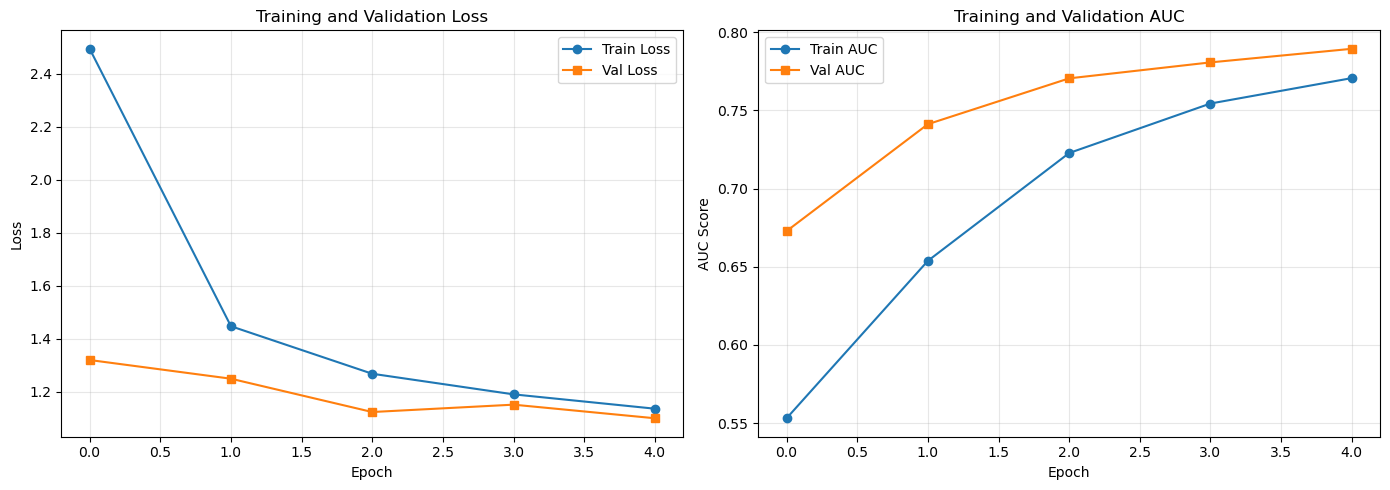

Evaluating: 100%|██████████| 701/701 [04:50<00:00,  2.42it/s]



Per-Class AUC Scores
Atelectasis                   : 0.7711
Cardiomegaly                  : 0.8693
Consolidation                 : 0.7672
Edema                         : 0.8846
Effusion                      : 0.8534
Emphysema                     : 0.8638
Fibrosis                      : 0.7693
Hernia                        : 0.8637
Infiltration                  : 0.6834
Mass                          : 0.7727
No Finding                    : 0.7558
Nodule                        : 0.6902
Pleural_Thickening            : 0.7541
Pneumonia                     : 0.7066
Pneumothorax                  : 0.8350


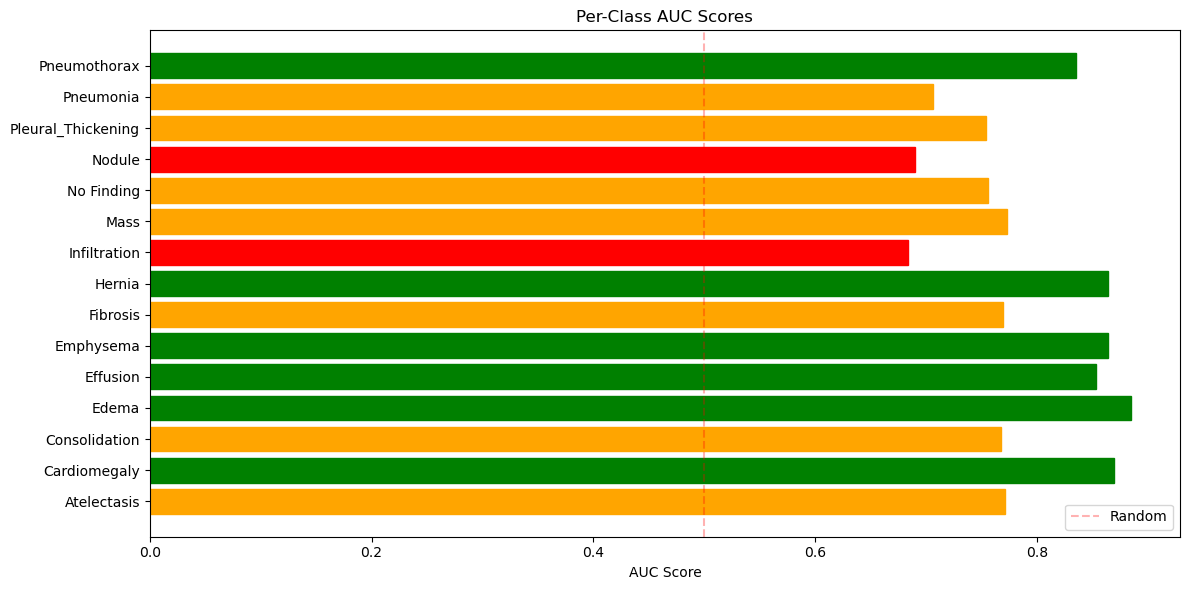


Macro-Average AUC: 0.7894


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add this helper function at the TOP of CELL 6
def safe_load_checkpoint(filepath):
    """Safely load checkpoint across different PyTorch versions"""
    try:
        return torch.load(filepath, weights_only=False)
    except:
        try:
            import numpy as np
            torch.serialization.add_safe_globals([np.core.multiarray.scalar])
            return torch.load(filepath, weights_only=True)
        except:
            return torch.load(filepath, weights_only=False, map_location=device)

def plot_training_history(history):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot loss
    axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
    axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot AUC
    axes[1].plot(history['train_auc'], label='Train AUC', marker='o')
    axes[1].plot(history['val_auc'], label='Val AUC', marker='s')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('AUC Score')
    axes[1].set_title('Training and Validation AUC')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def evaluate_model_detailed(model, loader):
    """Detailed evaluation with per-class metrics"""
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels, _ in tqdm(loader, desc='Evaluating'):
            images = images.to(device)
            outputs = model(images)
            preds = torch.sigmoid(outputs)
            all_preds.append(preds.cpu())
            all_labels.append(labels)
    
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    
    # Get disease names
    disease_names = temp_dataset.labels.columns.tolist()
    
    # Calculate per-class AUC
    print("\n" + "="*60)
    print("Per-Class AUC Scores")
    print("="*60)
    
    auc_scores = {}
    for i, disease in enumerate(disease_names):
        if len(np.unique(all_labels[:, i])) > 1:
            auc = roc_auc_score(all_labels[:, i], all_preds[:, i])
            auc_scores[disease] = auc
            print(f"{disease:<30}: {auc:.4f}")
    
    # Plot per-class AUC
    plt.figure(figsize=(12, 6))
    diseases = list(auc_scores.keys())
    scores = list(auc_scores.values())
    
    bars = plt.barh(range(len(diseases)), scores)
    plt.yticks(range(len(diseases)), diseases)
    plt.xlabel('AUC Score')
    plt.title('Per-Class AUC Scores')
    plt.axvline(x=0.5, color='r', linestyle='--', alpha=0.3, label='Random')
    
    # Color bars based on performance
    for i, (bar, score) in enumerate(zip(bars, scores)):
        if score >= 0.8:
            bar.set_color('green')
        elif score >= 0.7:
            bar.set_color('orange')
        else:
            bar.set_color('red')
    
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    return auc_scores

# Load best model for evaluation (use safe loader)
checkpoint = safe_load_checkpoint('best_model_subset.pth')
model.load_state_dict(checkpoint['model_state_dict'])

# Plot training history
if 'history' in checkpoint:
    plot_training_history(checkpoint['history'])
else:
    plot_training_history(history)  # Use current history if not in checkpoint

# Detailed evaluation on validation set
auc_scores = evaluate_model_detailed(model, val_loader_subset)

# Calculate and print macro-average AUC
macro_auc = np.mean(list(auc_scores.values()))
print(f"\n{'='*60}")
print(f"Macro-Average AUC: {macro_auc:.4f}")
print(f"{'='*60}")

In [30]:
def predict_single_image(model, image_path, transform=transform_val):
    """Make prediction on a single chest X-ray image"""
    model.eval()
    
    # Load and preprocess image
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    # Get prediction
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.sigmoid(output).cpu().numpy()[0]
    
    # Get disease names
    disease_names = temp_dataset.labels.columns.tolist()
    
    # Create results DataFrame
    results = pd.DataFrame({
        'Disease': disease_names,
        'Probability': probabilities
    })
    results = results.sort_values('Probability', ascending=False)
    
    # Display image with predictions
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Show image
    ax1.imshow(image, cmap='gray')
    ax1.set_title('Chest X-ray Image')
    ax1.axis('off')
    
    # Show predictions
    top_n = 10
    diseases_top = results['Disease'].values[:top_n][::-1]
    probs_top = results['Probability'].values[:top_n][::-1]
    
    colors = ['green' if p > 0.5 else 'gray' for p in probs_top]
    bars = ax2.barh(range(top_n), probs_top, color=colors)
    ax2.set_yticks(range(top_n))
    ax2.set_yticklabels(diseases_top)
    ax2.set_xlabel('Probability')
    ax2.set_title('Top Predicted Findings')
    ax2.set_xlim([0, 1])
    
    # Add threshold line
    ax2.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Threshold (0.5)')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()
    
    return results

# Example usage (uncomment and replace with your image path)
# results = predict_single_image(model, 'path/to/your/chest_xray.png')
# print(results.head(10))


STARTING HYBRID UNLEARNING PIPELINE

Configuration:
  Forget samples: 100
  Retain samples: 112020

STEP 1: Computing Influence Scores
Computing influence scores (simple method)...


Computing Influence: 100%|██████████| 7/7 [00:01<00:00,  5.28it/s]


✓ Computed influence for 100 samples


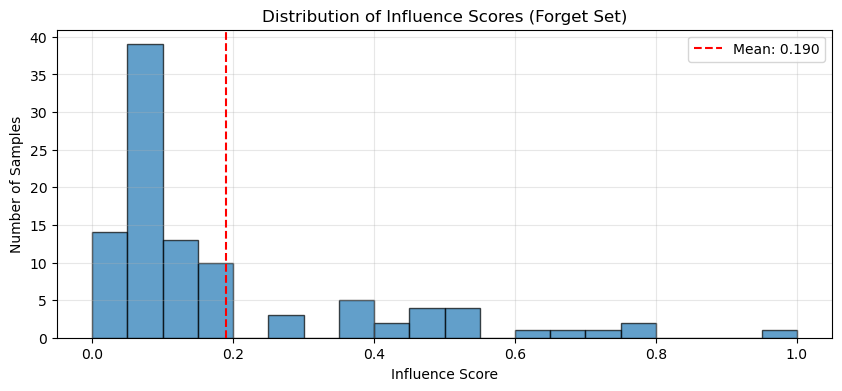


STEP 2: Hybrid Unlearning
Hybrid loader: 16 batches

HYBRID UNLEARNING (Influence + Gradient Reversal)
  Forget samples: 100
  Learning rate: 0.0001
  Epochs: 5


Hybrid Unlearning Epoch 1/5: 100%|██████████| 16/16 [00:07<00:00,  2.19it/s, retain=1.3830, forget=4.5951]



Epoch 1: Retain Loss=1.3830, Forget Loss=4.5951


Hybrid Unlearning Epoch 2/5: 100%|██████████| 16/16 [00:04<00:00,  3.90it/s, retain=1.3520, forget=4.9717]



Epoch 2: Retain Loss=1.3520, Forget Loss=4.9717


Hybrid Unlearning Epoch 3/5: 100%|██████████| 16/16 [00:04<00:00,  3.84it/s, retain=1.4666, forget=3.5798]


... (5 outputs left out)

Forget: 100%|██████████| 50/50 [00:00<00:00, 145.65it/s]


Evaluating RETAIN samples...


Retain: 100%|██████████| 50/50 [00:00<00:00, 151.04it/s]



UNLEARNING VERIFICATION RESULTS

Metric                    Forget Set      Retain Set     
-------------------------------------------------------
Avg Loss                  2.9311          1.5780         
Avg Confidence            0.2251          0.2297         

✓ Unlearning successful! (Forget loss > Retain loss)


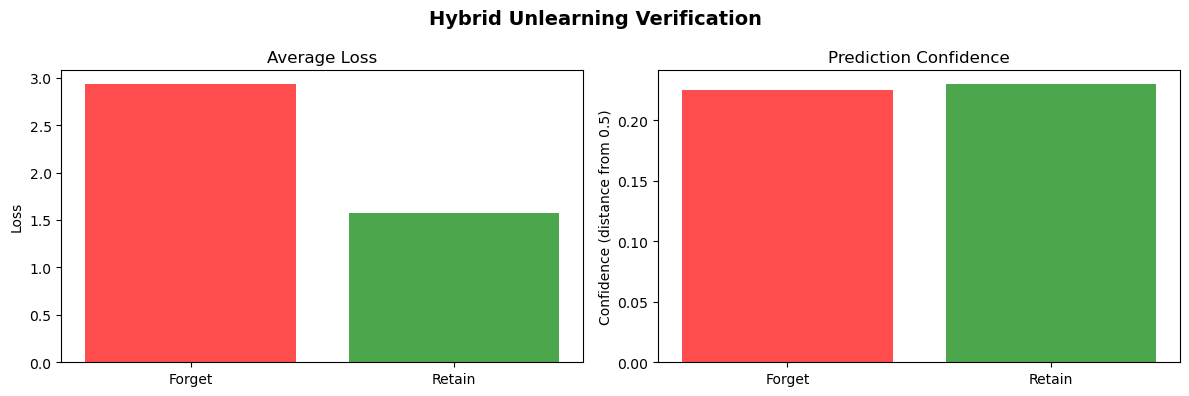

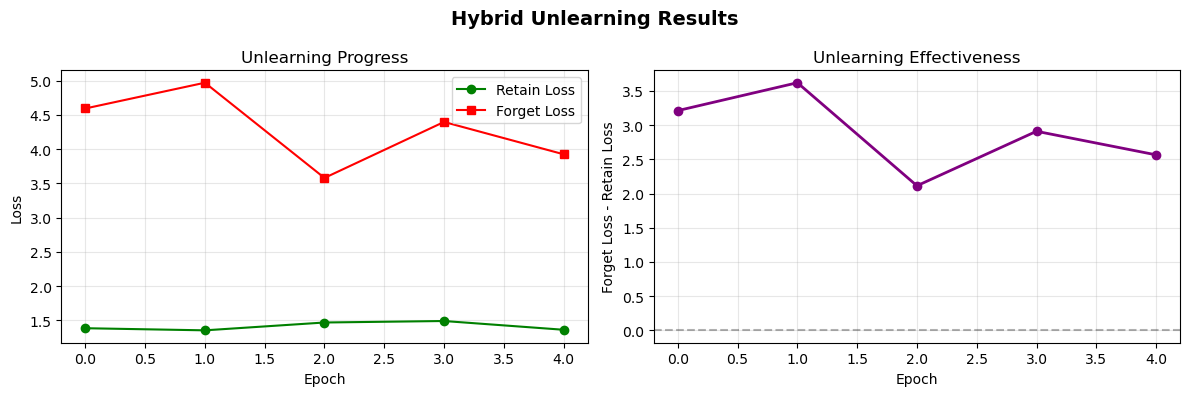


HYBRID UNLEARNING COMPLETE!


In [31]:
# ============================================
# STEP 1: COMPUTE INFLUENCE SCORES (FIXED)
# ============================================

def compute_influence_scores(model, loader, criterion):
    """
    Compute per-sample influence scores using gradient norms
    Higher score = sample has more influence on model
    """
    model.eval()
    influence_scores = {}
    
    print("Computing influence scores...")
    for images, labels, indices in tqdm(loader, desc='Computing Influence'):
        images = images.to(device)
        labels = labels.to(device)
        images.requires_grad = True
        
        model.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Compute gradients w.r.t model parameters (with allow_unused=True)
        grads = torch.autograd.grad(
            loss, 
            model.parameters(), 
            create_graph=False,
            allow_unused=True  # FIX: Allow unused parameters
        )
        
        # Calculate per-sample influence based on gradient magnitude
        for i, idx in enumerate(indices):
            sample_grad_norm = 0
            for g in grads:
                if g is not None:  # FIX: Check if gradient exists
                    sample_grad_norm += g.norm().item()
            
            influence_scores[int(idx)] = sample_grad_norm
    
    # Normalize influence scores to [0, 1] range
    if influence_scores:
        max_score = max(influence_scores.values())
        min_score = min(influence_scores.values())
        if max_score > min_score:
            for k in influence_scores:
                influence_scores[k] = (influence_scores[k] - min_score) / (max_score - min_score)
        else:
            for k in influence_scores:
                influence_scores[k] = 0.5
    
    print(f"✓ Computed influence for {len(influence_scores)} samples")
    print(f"  Score range: [{min(influence_scores.values()):.4f}, {max(influence_scores.values()):.4f}]")
    
    return influence_scores


# ============================================
# ALTERNATIVE: Simpler influence computation
# ============================================

def compute_influence_simple(model, loader, criterion):
    """
    Simpler influence computation using per-sample loss
    """
    model.eval()
    influence_scores = {}
    
    print("Computing influence scores (simple method)...")
    with torch.no_grad():
        for images, labels, indices in tqdm(loader, desc='Computing Influence'):
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            
            # Compute per-sample loss
            for i, idx in enumerate(indices):
                sample_output = outputs[i:i+1]
                sample_label = labels[i:i+1]
                loss = criterion(sample_output, sample_label)
                influence_scores[int(idx)] = loss.item()
    
    # Normalize
    if influence_scores:
        max_score = max(influence_scores.values())
        min_score = min(influence_scores.values())
        if max_score > min_score:
            for k in influence_scores:
                influence_scores[k] = (influence_scores[k] - min_score) / (max_score - min_score)
        else:
            for k in influence_scores:
                influence_scores[k] = 0.5
    
    print(f"✓ Computed influence for {len(influence_scores)} samples")
    return influence_scores


# ============================================
# STEP 2: INFLUENCE-WEIGHTED GRADIENT REVERSAL
# ============================================

def hybrid_unlearning_step(model, images, labels, indices, forget_indices, 
                           influence_scores, criterion, optimizer):
    """
    Single step of hybrid unlearning:
    - Forget samples: Reverse gradients weighted by influence scores
    - Retain samples: Normal gradient descent
    """
    retain_mask = torch.tensor([int(idx) not in forget_indices for idx in indices])
    forget_mask = ~retain_mask
    
    # Skip batch if no forget samples
    if forget_mask.sum() == 0:
        return None, None
    
    optimizer.zero_grad()
    outputs = model(images)
    
    forget_loss_val = None
    retain_loss_val = None
    
    # Process retain samples (minimize loss)
    if retain_mask.sum() > 0:
        retain_loss = criterion(outputs[retain_mask], labels[retain_mask])
        retain_loss.backward(retain_graph=True)
        retain_loss_val = retain_loss.item()
    
    # Process forget samples (maximize loss with influence weighting)
    if forget_mask.sum() > 0:
        forget_indices_batch = [int(idx) for i, idx in enumerate(indices) if forget_mask[i]]
        
        # Get influence scores for these forget samples
        sample_influence = torch.tensor([
            influence_scores.get(idx, 0.5) for idx in forget_indices_batch
        ]).to(device)
        
        # Normalize influence weights
        if sample_influence.sum() > 0:
            sample_influence = sample_influence / sample_influence.sum()
        
        # Compute per-sample loss with influence weighting
        forget_outputs = outputs[forget_mask]
        forget_labels = labels[forget_mask]
        
        # Weighted loss: high influence samples get stronger gradient reversal
        per_sample_loss = criterion(forget_outputs, forget_labels)
        weighted_loss = (per_sample_loss * sample_influence).sum()
        
        # Reverse gradients (negative loss = maximize loss)
        (-weighted_loss).backward()
        forget_loss_val = weighted_loss.item()
    
    # Gradient clipping for stability
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    
    # Update model
    optimizer.step()
    
    return retain_loss_val, forget_loss_val


def hybrid_unlearning(model, train_loader, forget_indices, influence_scores, 
                      criterion, epochs=5, lr=1e-4):
    """
    Complete hybrid unlearning pipeline
    """
    model.train()
    
    # Use SGD with momentum for stable unlearning
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-5)
    
    print("\n" + "="*60)
    print("HYBRID UNLEARNING (Influence + Gradient Reversal)")
    print("="*60)
    print(f"  Forget samples: {len(forget_indices)}")
    print(f"  Learning rate: {lr}")
    print(f"  Epochs: {epochs}")
    print("="*60)
    
    history = {
        'retain_loss': [],
        'forget_loss': []
    }
    
    for epoch in range(epochs):
        total_retain_loss = 0
        total_forget_loss = 0
        retain_batches = 0
        forget_batches = 0
        
        pbar = tqdm(train_loader, desc=f'Hybrid Unlearning Epoch {epoch+1}/{epochs}')
        
        for images, labels, indices in pbar:
            images, labels = images.to(device), labels.to(device)
            
            retain_loss, forget_loss = hybrid_unlearning_step(
                model, images, labels, indices, forget_indices,
                influence_scores, criterion, optimizer
            )
            
            if retain_loss is not None:
                total_retain_loss += retain_loss
                retain_batches += 1
            
            if forget_loss is not None:
                total_forget_loss += forget_loss
                forget_batches += 1
            
            # Update progress bar
            pbar.set_postfix({
                'retain': f'{total_retain_loss/max(1, retain_batches):.4f}',
                'forget': f'{total_forget_loss/max(1, forget_batches):.4f}'
            })
        
        # Calculate epoch metrics
        avg_retain_loss = total_retain_loss / max(1, retain_batches)
        avg_forget_loss = total_forget_loss / max(1, forget_batches)
        
        history['retain_loss'].append(avg_retain_loss)
        history['forget_loss'].append(avg_forget_loss)
        
        print(f"\nEpoch {epoch+1}: Retain Loss={avg_retain_loss:.4f}, Forget Loss={avg_forget_loss:.4f}")
    
    print("\n✓ Hybrid unlearning completed!")
    return model, history


# ============================================
# STEP 3: VERIFY UNLEARNING (FINAL FIX)
# ============================================

def verify_hybrid_unlearning(model, dataset, forget_indices, retain_indices, 
                             criterion, num_samples=50):
    """
    Comprehensive verification of hybrid unlearning effectiveness
    """
    model.eval()
    
    print("\n" + "="*60)
    print("VERIFYING HYBRID UNLEARNING")
    print("="*60)
    
    # Sample indices
    forget_sample = list(forget_indices)[:num_samples]
    retain_sample = list(retain_indices)[:num_samples]
    
    results = {
        'forget_losses': [],
        'retain_losses': [],
        'forget_preds': [],
        'retain_preds': []
    }
    
    # Use validation transform for evaluation
    eval_transform = transform_val
    
    # Evaluate forget samples
    print("\nEvaluating FORGET samples...")
    for idx in tqdm(forget_sample, desc='Forget'):
        # Get image and label directly from dataset
        image, label, _ = dataset[idx]  # dataset is already ChestXrayDataset
        
        # If image is already a tensor, skip transform
        if isinstance(image, torch.Tensor):
            image = image.unsqueeze(0).to(device)
        else:
            # If image is PIL Image, apply transform
            image = eval_transform(image).unsqueeze(0).to(device)
        
        label = label.unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(image)
            loss = criterion(output, label)
            pred = torch.sigmoid(output).cpu().numpy()[0]
            
            results['forget_losses'].append(loss.item())
            results['forget_preds'].append(pred)
    
    # Evaluate retain samples
    print("Evaluating RETAIN samples...")
    for idx in tqdm(retain_sample, desc='Retain'):
        # Get image and label directly from dataset
        image, label, _ = dataset[idx]
        
        # If image is already a tensor, skip transform
        if isinstance(image, torch.Tensor):
            image = image.unsqueeze(0).to(device)
        else:
            # If image is PIL Image, apply transform
            image = eval_transform(image).unsqueeze(0).to(device)
        
        label = label.unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(image)
            loss = criterion(output, label)
            pred = torch.sigmoid(output).cpu().numpy()[0]
            
            results['retain_losses'].append(loss.item())
            results['retain_preds'].append(pred)
    
    # Calculate metrics
    avg_forget_loss = np.mean(results['forget_losses'])
    avg_retain_loss = np.mean(results['retain_losses'])
    
    forget_preds_array = np.array(results['forget_preds'])
    retain_preds_array = np.array(results['retain_preds'])
    
    forget_confidence = np.mean(np.abs(forget_preds_array - 0.5))
    retain_confidence = np.mean(np.abs(retain_preds_array - 0.5))
    
    # Print results
    print("\n" + "="*60)
    print("UNLEARNING VERIFICATION RESULTS")
    print("="*60)
    print(f"\n{'Metric':<25} {'Forget Set':<15} {'Retain Set':<15}")
    print("-"*55)
    print(f"{'Avg Loss':<25} {avg_forget_loss:<15.4f} {avg_retain_loss:<15.4f}")
    print(f"{'Avg Confidence':<25} {forget_confidence:<15.4f} {retain_confidence:<15.4f}")
    
    # Success check
    if avg_forget_loss > avg_retain_loss:
        print("\n✓ Unlearning successful! (Forget loss > Retain loss)")
    else:
        print("\n⚠ Unlearning may need more epochs")
    
    # Plot comparison
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    axes[0].bar(['Forget', 'Retain'], [avg_forget_loss, avg_retain_loss], 
                color=['red', 'green'], alpha=0.7)
    axes[0].set_title('Average Loss')
    axes[0].set_ylabel('Loss')
    
    axes[1].bar(['Forget', 'Retain'], [forget_confidence, retain_confidence], 
                color=['red', 'green'], alpha=0.7)
    axes[1].set_title('Prediction Confidence')
    axes[1].set_ylabel('Confidence (distance from 0.5)')
    
    plt.suptitle('Hybrid Unlearning Verification', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return results


# ============================================
# EXECUTE HYBRID UNLEARNING (FINAL)
# ============================================

print("\n" + "="*60)
print("STARTING HYBRID UNLEARNING PIPELINE")
print("="*60)

# Define forget and retain indices
forget_indices = set(range(100))  # Forget first 100 samples
retain_indices = set(range(100, len(dataset)))

print(f"\nConfiguration:")
print(f"  Forget samples: {len(forget_indices)}")
print(f"  Retain samples: {len(retain_indices)}")

# Step 1: Compute influence scores
print("\n" + "="*60)
print("STEP 1: Computing Influence Scores")
print("="*60)

forget_subset = TransformedSubset(dataset, list(forget_indices), transform_val)
forget_loader_influence = DataLoader(
    forget_subset, 
    batch_size=16, 
    shuffle=False, 
    num_workers=0
)

influence_scores = compute_influence_simple(
    model, forget_loader_influence, criterion
)

# Visualize influence distribution
plt.figure(figsize=(10, 4))
plt.hist(list(influence_scores.values()), bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('Influence Score')
plt.ylabel('Number of Samples')
plt.title('Distribution of Influence Scores (Forget Set)')
plt.axvline(x=np.mean(list(influence_scores.values())), color='red', 
            linestyle='--', label=f'Mean: {np.mean(list(influence_scores.values())):.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Step 2: Apply hybrid unlearning
print("\n" + "="*60)
print("STEP 2: Hybrid Unlearning")
print("="*60)

# Create balanced loader (1:4 forget:retain ratio)
hybrid_indices = list(forget_indices) + list(retain_indices)[:400]
hybrid_dataset = TransformedSubset(dataset, hybrid_indices, transform_train)
hybrid_loader = DataLoader(
    hybrid_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=0
)

print(f"Hybrid loader: {len(hybrid_loader)} batches")

model, unlearning_history = hybrid_unlearning(
    model=model,
    train_loader=hybrid_loader,
    forget_indices=forget_indices,
    influence_scores=influence_scores,
    criterion=criterion,
    epochs=5,
    lr=1e-4
)

# Step 3: Verify unlearning
print("\n" + "="*60)
print("STEP 3: Verification")
print("="*60)

verification_results = verify_hybrid_unlearning(
    model=model,
    dataset=dataset,  # Original ChestXrayDataset (no transform)
    forget_indices=forget_indices,
    retain_indices=retain_indices,
    criterion=criterion,
    num_samples=50
)

# Step 4: Plot unlearning progress
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(unlearning_history['retain_loss'], label='Retain Loss', marker='o', color='green')
axes[0].plot(unlearning_history['forget_loss'], label='Forget Loss', marker='s', color='red')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Unlearning Progress')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

loss_diff = [f - r for f, r in zip(unlearning_history['forget_loss'], 
                                     unlearning_history['retain_loss'])]
axes[1].plot(loss_diff, marker='o', color='purple', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Forget Loss - Retain Loss')
axes[1].set_title('Unlearning Effectiveness')
axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.3)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Hybrid Unlearning Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("HYBRID UNLEARNING COMPLETE!")
print("="*60)

VERIFYING UNLEARNING EFFECTIVENESS

Predictions on FORGET samples (should be uncertain/near random):
  Average Loss: 5.3790
  Average Confidence: 0.2736 (lower = more uncertain)

Predictions on RETAIN samples (should remain accurate):
  Average Loss: 1.5822
  Average Confidence: 0.2469 (higher = more certain)

SUMMARY:
  Forget Loss: 5.3790 | Retain Loss: 1.5822
  Forget Confidence: 0.2736 | Retain Confidence: 0.2469
  ✓ Unlearning appears successful (forget loss > retain loss)


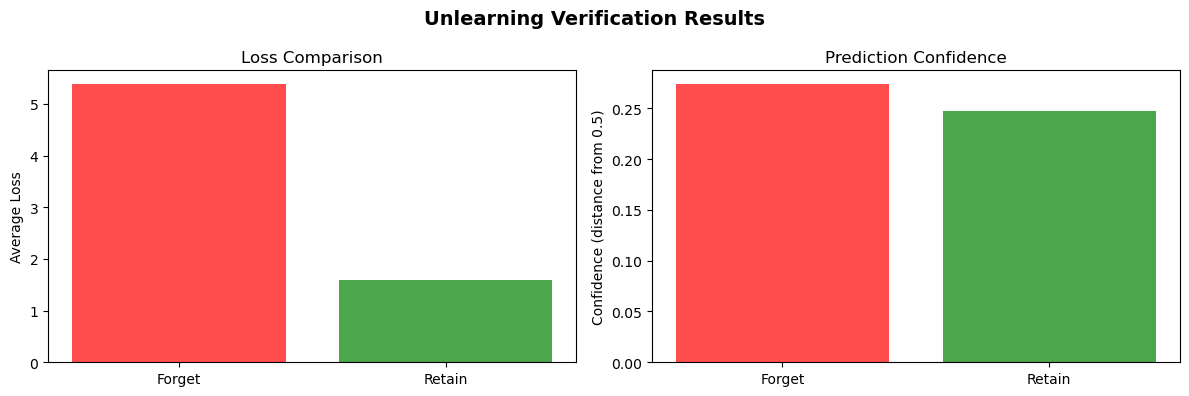

In [32]:
def verify_unlearning(model, dataset, forget_indices, retain_indices):
    """Verify that unlearning was effective"""
    model.eval()
    
    print("="*60)
    print("VERIFYING UNLEARNING EFFECTIVENESS")
    print("="*60)
    
    # Use validation transform
    eval_transform = transform_val
    
    # Check predictions on forget samples
    print("\nPredictions on FORGET samples (should be uncertain/near random):")
    forget_losses = []
    forget_preds = []
    
    for idx in list(forget_indices)[:20]:  # Sample first 20
        image, label, _ = dataset[idx]
        
        # Apply transform to convert PIL Image to tensor
        if not isinstance(image, torch.Tensor):
            image = eval_transform(image)
        
        image = image.unsqueeze(0).to(device)
        label = label.unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(image)
            loss = criterion(output, label)
            pred = torch.sigmoid(output).cpu().numpy()[0]
            
            forget_losses.append(loss.item())
            forget_preds.append(pred)
    
    avg_forget_loss = np.mean(forget_losses)
    forget_preds = np.array(forget_preds)
    forget_confidence = np.mean(np.abs(forget_preds - 0.5))  # Distance from 0.5
    
    print(f"  Average Loss: {avg_forget_loss:.4f}")
    print(f"  Average Confidence: {forget_confidence:.4f} (lower = more uncertain)")
    
    # Check predictions on retain samples
    print("\nPredictions on RETAIN samples (should remain accurate):")
    retain_losses = []
    retain_preds = []
    
    for idx in list(retain_indices)[:20]:  # Sample first 20
        image, label, _ = dataset[idx]
        
        # Apply transform to convert PIL Image to tensor
        if not isinstance(image, torch.Tensor):
            image = eval_transform(image)
        
        image = image.unsqueeze(0).to(device)
        label = label.unsqueeze(0).to(device)
        
        with torch.no_grad():
            output = model(image)
            loss = criterion(output, label)
            pred = torch.sigmoid(output).cpu().numpy()[0]
            
            retain_losses.append(loss.item())
            retain_preds.append(pred)
    
    avg_retain_loss = np.mean(retain_losses)
    retain_preds = np.array(retain_preds)
    retain_confidence = np.mean(np.abs(retain_preds - 0.5))
    
    print(f"  Average Loss: {avg_retain_loss:.4f}")
    print(f"  Average Confidence: {retain_confidence:.4f} (higher = more certain)")
    
    # Summary
    print("\n" + "="*60)
    print("SUMMARY:")
    print(f"  Forget Loss: {avg_forget_loss:.4f} | Retain Loss: {avg_retain_loss:.4f}")
    print(f"  Forget Confidence: {forget_confidence:.4f} | Retain Confidence: {retain_confidence:.4f}")
    
    if avg_forget_loss > avg_retain_loss:
        print("  ✓ Unlearning appears successful (forget loss > retain loss)")
    else:
        print("  ⚠ Unlearning may need more epochs")
    
    # Visual comparison
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Loss comparison
    axes[0].bar(['Forget', 'Retain'], [avg_forget_loss, avg_retain_loss], 
                color=['red', 'green'], alpha=0.7)
    axes[0].set_ylabel('Average Loss')
    axes[0].set_title('Loss Comparison')
    
    # Confidence comparison
    axes[1].bar(['Forget', 'Retain'], [forget_confidence, retain_confidence], 
                color=['red', 'green'], alpha=0.7)
    axes[1].set_ylabel('Confidence (distance from 0.5)')
    axes[1].set_title('Prediction Confidence')
    
    plt.suptitle('Unlearning Verification Results', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("="*60)

# Verify unlearning
verify_unlearning(model, dataset, forget_indices, retain_indices)

In [33]:
def save_model_for_inference(model, save_path='unlearned_model.pth'):
    """Save model for later use"""
    disease_names = temp_dataset.labels.columns.tolist()
    
    checkpoint = {
        'model_state_dict': model.state_dict(),
        'disease_names': disease_names,
        'num_classes': len(disease_names),
        'model_config': {
            'architecture': 'ChestXrayResNet',
            'input_size': (224, 224),
            'normalization': {
                'mean': [0.485, 0.456, 0.406],
                'std': [0.229, 0.224, 0.225]
            }
        }
    }
    
    torch.save(checkpoint, save_path)
    print(f"✓ Model saved to {save_path}")
    print(f"  Diseases: {len(disease_names)} classes")
    print(f"  Architecture: ChestXrayResNet")

# Save the unlearned model
save_model_for_inference(model, 'unlearned_model.pth')

print("\n" + "="*60)
print("COMPLETE PIPELINE FINISHED!")
print("="*60)
print("Steps completed:")
print("  1. ✓ Data loading with augmentation")
print("  2. ✓ Model training with early stopping")
print("  3. ✓ Model evaluation (AUC metrics)")
print("  4. ✓ Machine unlearning via gradient reversal")
print("  5. ✓ Unlearning verification")
print("  6. ✓ Model saved for future use")

✓ Model saved to unlearned_model.pth
  Diseases: 15 classes
  Architecture: ChestXrayResNet

COMPLETE PIPELINE FINISHED!
Steps completed:
  1. ✓ Data loading with augmentation
  2. ✓ Model training with early stopping
  3. ✓ Model evaluation (AUC metrics)
  4. ✓ Machine unlearning via gradient reversal
  5. ✓ Unlearning verification
  6. ✓ Model saved for future use
